In [1]:
import os, subprocess
import json
import uproot3
import awkward as ak
import numpy as np
from coffea import processor, util, hist
import pickle
import pandas as pd

from plotter import *

In [2]:
lumis = {}
lumis['2016'] = 35.9
lumis['2017'] = 41.5
lumis['2018'] = 59.9

with open('xsec.json') as f:
  xs = json.load(f)

with open('pmap.json') as f:
  pmap = json.load(f)

In [3]:
year = '2017'
nfiles = len(subprocess.getoutput("ls infiles-split/"+year+"*.json").split())
outsum = processor.dict_accumulator()

In [4]:
picklename = 'pickles/'+str(year)+'_templates.pkl'

In [5]:
# Read the histogram from the pickle file

ggf = pickle.load(open(picklename,'rb')).integrate('region','signal-ggf').integrate('systematic','nominal')
vbf = pickle.load(open(picklename,'rb')).integrate('region','signal-vbf').integrate('systematic','nominal')

In [6]:
def significance(s,b):
    if b==0:
        return 0
    z_squared = 2.0*(s+b)*np.log(1.0+1.0*s/b) - 2.0*s
    return np.sqrt(z_squared)

In [7]:
vbf

<Hist (process,pt1,msd1,ddb1) instance at 0x7f63bafec550>

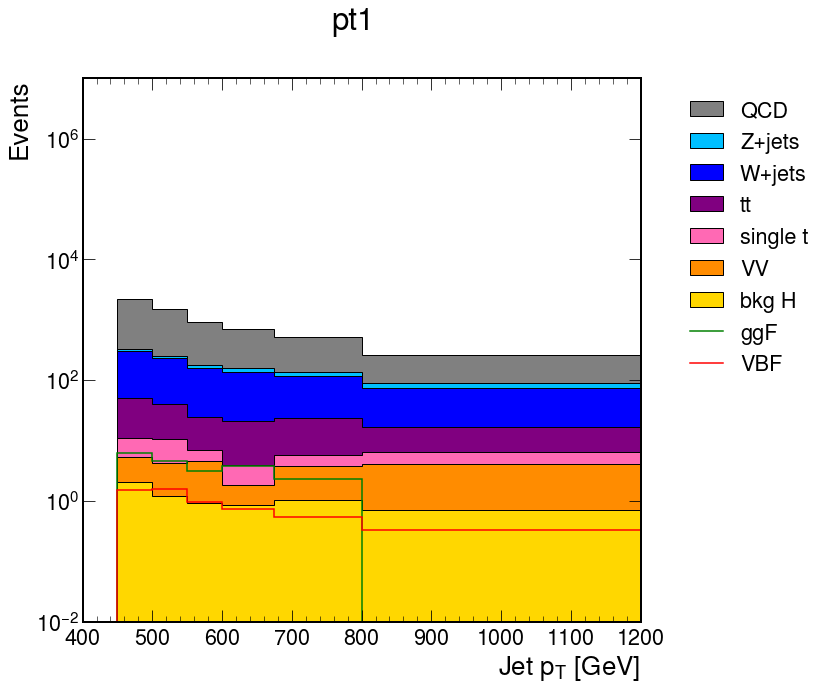

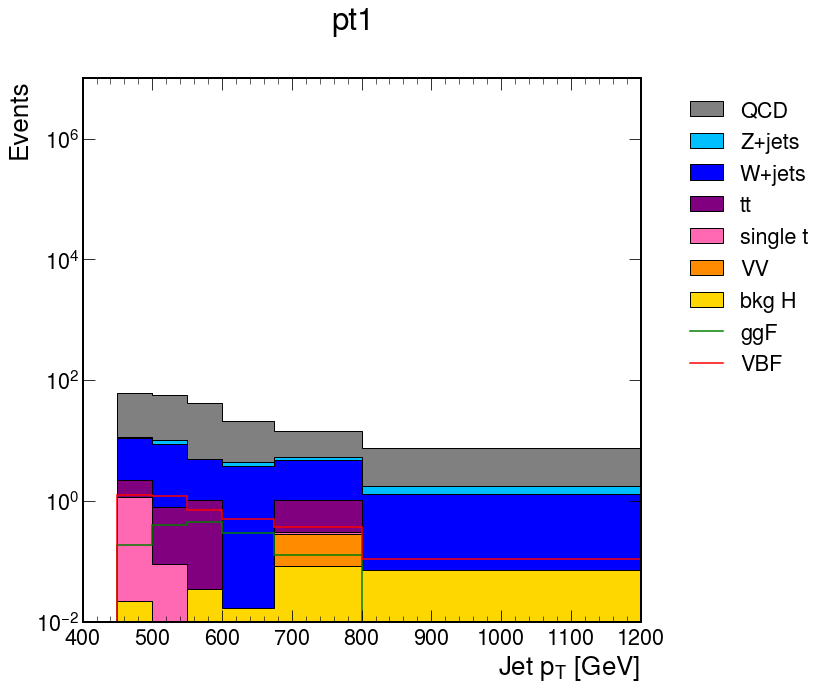

In [8]:
plot_mconly_ggfvbf(ggf.sum('msd1').integrate('ddb1',int_range=slice(0.7,1)),year+'/pt1_ggfcat','pt1')
plot_mconly_ggfvbf(vbf.sum('msd1').integrate('ddb1',int_range=slice(0.7,1)),year+'/pt1_vbfcat','pt1')

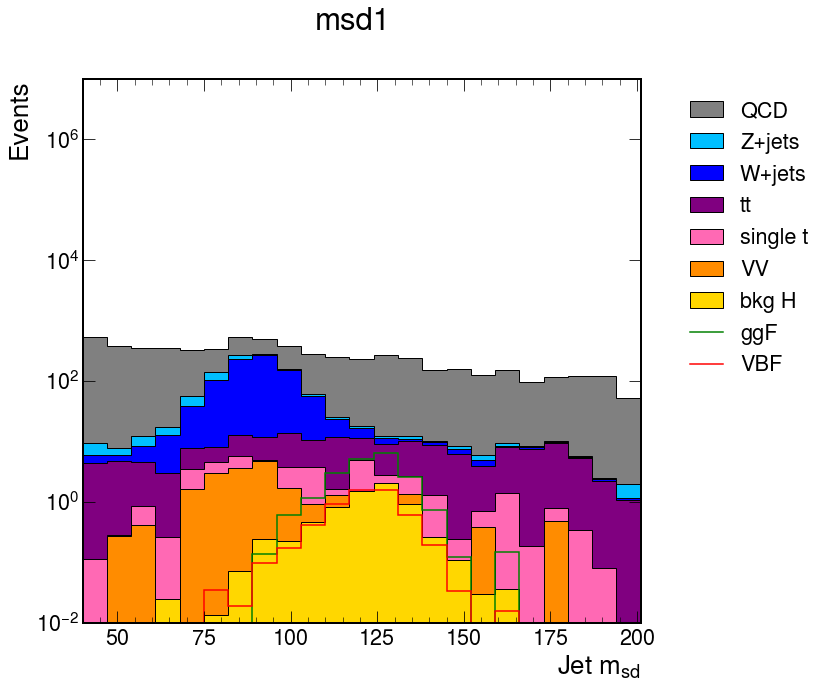

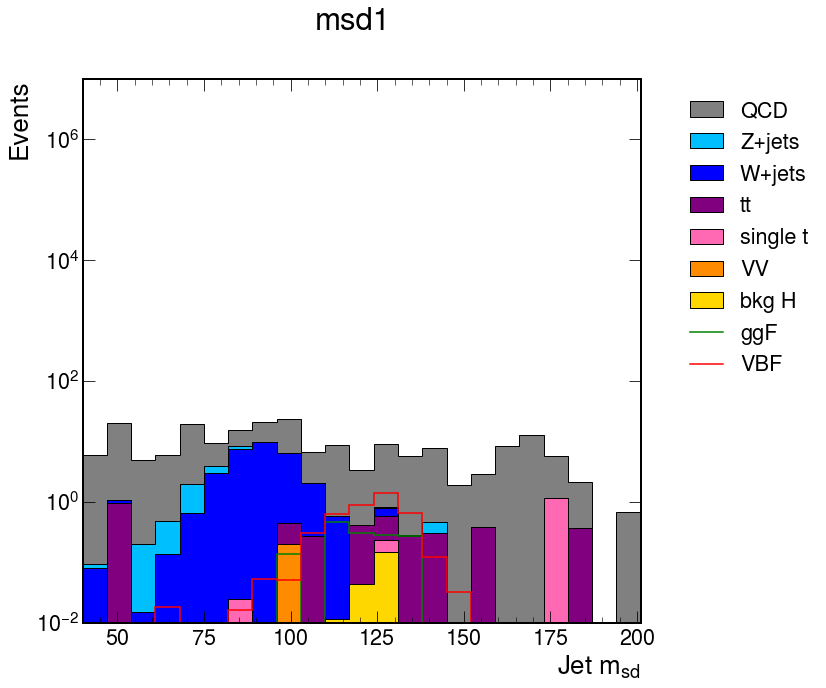

In [9]:
plot_mconly_ggfvbf(ggf.sum('pt1').integrate('ddb1',int_range=slice(0.7,1)),year+'/msd1_ggfcat','msd1')
plot_mconly_ggfvbf(vbf.sum('pt1').integrate('ddb1',int_range=slice(0.7,1)),year+'/msd1_vbfcat','msd1')

In [10]:
# number counting significance only makes sense in the mass window of Higgs
mbb_min = 110
mbb_max = 138

ddbthr = 0.7

ggf_window=ggf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(ddbthr,1))
vbf_window=vbf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(ddbthr,1))

In [11]:
ggf_sr = ggf_window.values()
vbf_sr = vbf_window.values()

In [12]:
# VBF significance
s1 = ggf_sr[('VBF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('ggF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('VBF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('ggF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

0.14729872143843342 0.654487364513743 0.6708581248263618


In [13]:
# ggF significance
s1 = ggf_sr[('ggF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('VBF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('ggF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('VBF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

# this only makes sense in the mass window of Higgs

0.5414636805856702 0.2388916726723314 0.5918210444598646


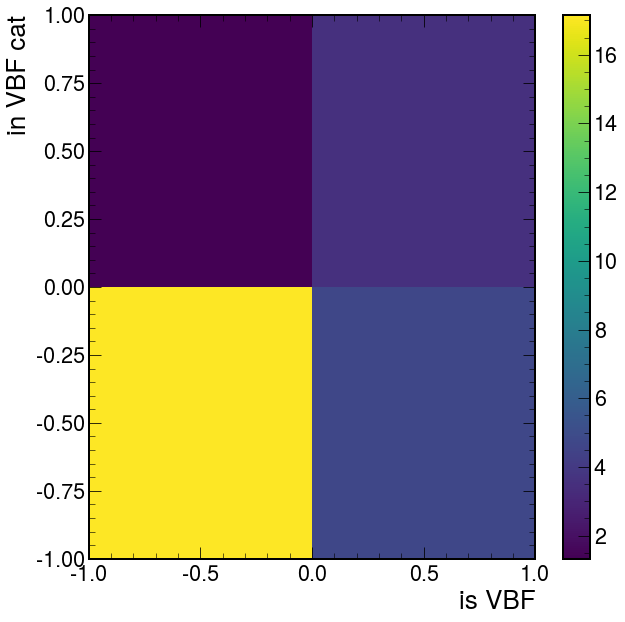

In [14]:
plt.hist2d(x=[-1,-1,1,1],y=[-1,1,-1,1],density=False, weights=[ggf_sr[('ggF',)] ,vbf_sr[('ggF',)] ,ggf_sr[('VBF',)] ,vbf_sr[('VBF',)]],bins=[2,2]);
plt.xlabel('is VBF');
plt.ylabel('in VBF cat');
plt.colorbar()
plt.savefig(year+'/confusion.png')

In [15]:
print(ggf_sr[('ggF',)] ,vbf_sr[('ggF',)] ,ggf_sr[('VBF',)] ,vbf_sr[('VBF',)])

17.152682065147857 1.3261252780365014 4.685500486642467 3.5437143780380436


In [18]:
ggf.sum('pt1','msd1').integrate('ddb1',int_range=slice(ddbthr,1)).values()

{('ZH',): 2.2952022468428597,
 ('WH',): 3.1003886535299516,
 ('ttH',): 1.3935011376075916,
 ('VBF',): 5.666166308498767,
 ('ggF',): 20.065815794630467,
 ('ggF-powheg',): 42.63370560439071,
 ('QCD',): 4928.332057498931,
 ('VV',): 16.99867759028348,
 ('Wjets',): 134.39853263953114,
 ('Zjets',): 835.5514361352093,
 ('ttbar',): 131.99014278612373,
 ('singlet',): 20.90911215095907,
 ('data',): 5036.0,
 ('muondata',): 433.0}

In [19]:
ggf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0,ddbthr)).values()

{('ZH',): 14.474303851319338,
 ('WH',): 17.988573011551285,
 ('ttH',): 20.33603926598054,
 ('VBF',): 15.289121025573325,
 ('ggF',): 61.8484742589393,
 ('ggF-powheg',): 121.34407215065174,
 ('QCD',): 4972715.934795209,
 ('VV',): 1481.0640486643701,
 ('Wjets',): 100165.3269946587,
 ('Zjets',): 41555.50992368689,
 ('ttbar',): 19725.04213525653,
 ('singlet',): 3231.6106525035293,
 ('data',): 4547376.0,
 ('muondata',): 79152.0}

In [20]:
vbf.sum('pt1','msd1').integrate('ddb1',int_range=slice(ddbthr,1)).values()

{('ZH',): 0.016047401255889958,
 ('WH',): 0.1707877416632257,
 ('ttH',): 0.049655620124262834,
 ('VBF',): 4.138179092719266,
 ('ggF',): 1.464352489590503,
 ('ggF-powheg',): 1.9101853345436148,
 ('QCD',): 162.8361947876927,
 ('VV',): 0.19981754283972206,
 ('Wjets',): 3.802803876692274,
 ('Zjets',): 29.596685880368575,
 ('ttbar',): 3.5243333793642195,
 ('singlet',): 1.2520700409033132,
 ('data',): 245.0,
 ('muondata',): 27.0}

In [21]:
vbf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0,ddbthr)).values()

{('ZH',): 0.21114601281559958,
 ('WH',): 0.3782052025236013,
 ('ttH',): 0.4732212224092055,
 ('VBF',): 11.371528306203794,
 ('ggF',): 2.0279209123678896,
 ('ggF-powheg',): 6.506957014305833,
 ('QCD',): 191346.78426733208,
 ('VV',): 47.42986624034679,
 ('Wjets',): 3716.249963278582,
 ('Zjets',): 1639.8546435321416,
 ('ttbar',): 661.9700510152396,
 ('singlet',): 140.36542543074933,
 ('data',): 197478.0,
 ('muondata',): 4845.0}